# Evidencia 5 — Semántica

SONORA · E5-01…05 · `lyrics_full_v1` / `e5-surface-v2`.
Resultados reales del corpus completo, con modelos ajustados sólo en train.
Validation selecciona; test se transforma y se comprueba numéricamente, sin
evaluación de relevancia. La muestra de PCA/contextos es de 2 000 letras de
validación y no sustituye el entrenamiento completo. Este notebook no reentrena.

In [1]:
import json
from pathlib import Path
from collections import Counter
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
REPORTS = ROOT / 'reports/nlp/lyrics_full_v1'
MODELS = ROOT / 'artifacts/models/lyrics_full_v1/e5-surface-v2'
def read(path):
    return json.loads(path.read_text(encoding='utf-8'))
def show(rows):
    if not rows:
        print('Sin resultados con soporte suficiente.')
        return
    keys = list(rows[0])
    text = '| ' + ' | '.join(keys) + ' |\n| ' + ' | '.join(['---']*len(keys)) + ' |\n'
    text += '\n'.join('| ' + ' | '.join(str(row[k]).replace('|', '/') for k in keys) + ' |' for row in rows)
    display(Markdown(text))
audit = read(REPORTS/'e5_verification.json')
analysis = read(REPORTS/'e5_analysis.json')
semantic = read(REPORTS/'e5_embedding_retrieval.json')
lexical = read(REPORTS/'e5_tfidf_retrieval.json')
assert audit['unique_ids'] == audit['counts']['docs'] == 3155772
assert audit['space_id'] == semantic['space_id']
assert audit['max_embedding_norm_error'] < 1e-5
assert audit['max_topic_sum_error'] < 1e-5
print('Auditoría real:', audit['verified_utc'])
print('Espacio común:', audit['space_id'])
show([{'split': s, 'letras': audit['counts']['docs_'+s], 'cobertura tokens': audit['token_coverage_by_split'][s]} for s in ('train','validation','test')])
print('No disponibles:', audit['counts']['embedding_unavailable'])
print('Errores máximos norma/suma:',audit['max_embedding_norm_error'],audit['max_topic_sum_error'])
print('Checkpoints con hashes comprobados:',audit['checkpoint_counts'])

Auditoría real: 2026-11-17T02:15:00+00:00
Espacio común: ec76a8c38600ad837729631f95a54d58ac2c983ae46c7259aded6897235d9479


| split | letras | cobertura tokens |
| --- | --- | --- |
| train | 2208832 | 0.8190104400958166 |
| validation | 315289 | 0.8187510846885268 |
| test | 631651 | 0.8187780875719013 |

No disponibles: 0
Errores máximos norma/suma: 1.7881393432617188e-07 1.0132789611816406e-06
Checkpoints con hashes comprobados: {'sgns5/sgns-window5': 4, 'sgns10/sgns-window10': 4, 'lda/lda-k20-seed42': 10, 'lda/lda-k40-seed42': 10, 'lda/lda-k20-seed43': 10}


## 1. Entrenamiento propio y selección (E5-01)

In [2]:
selection = read(MODELS/'sgns_selection.json')
show([{'ventana': c['window'], 'objetivo validation': c['mean_log_objective'], 'pares': c['positive_pairs']} for c in selection['candidates']])
print('Ventana seleccionada:', selection['selected']['window'])
print('Criterio:',selection['criterion'])
print('Dimensión 128; tres épocas completas de train; cuatro workers; TF-IDF sublineal y L2.')

| ventana | objetivo validation | pares |
| --- | --- | --- |
| 5 | -2.392892378162092 | 100000 |
| 10 | -2.4019780494344887 | 100000 |

Ventana seleccionada: 5
Criterio: largest validation mean SGNS log objective; same pairs/negatives
Dimensión 128; tres épocas completas de train; cuatro workers; TF-IDF sublineal y L2.


## 2. PCA de la muestra explícita de validación (E5-02)

{'method': 'PCA', 'svd_solver': 'full', 'n_components': 2, 'random_state': 42, 'fit_scope': 'validation visualization sample only', 'explained_variance_ratio': [0.23323145508766174, 0.09852376580238342]}
Varianza acumulada: 0.33175522089004517
Soportes por tag: {'rock': 414, 'pop': 851, 'rap': 584, 'rb': 106, 'country': 45}
Los 2 000 IDs, coordenadas, media y componentes se conservan en e5_analysis.json.


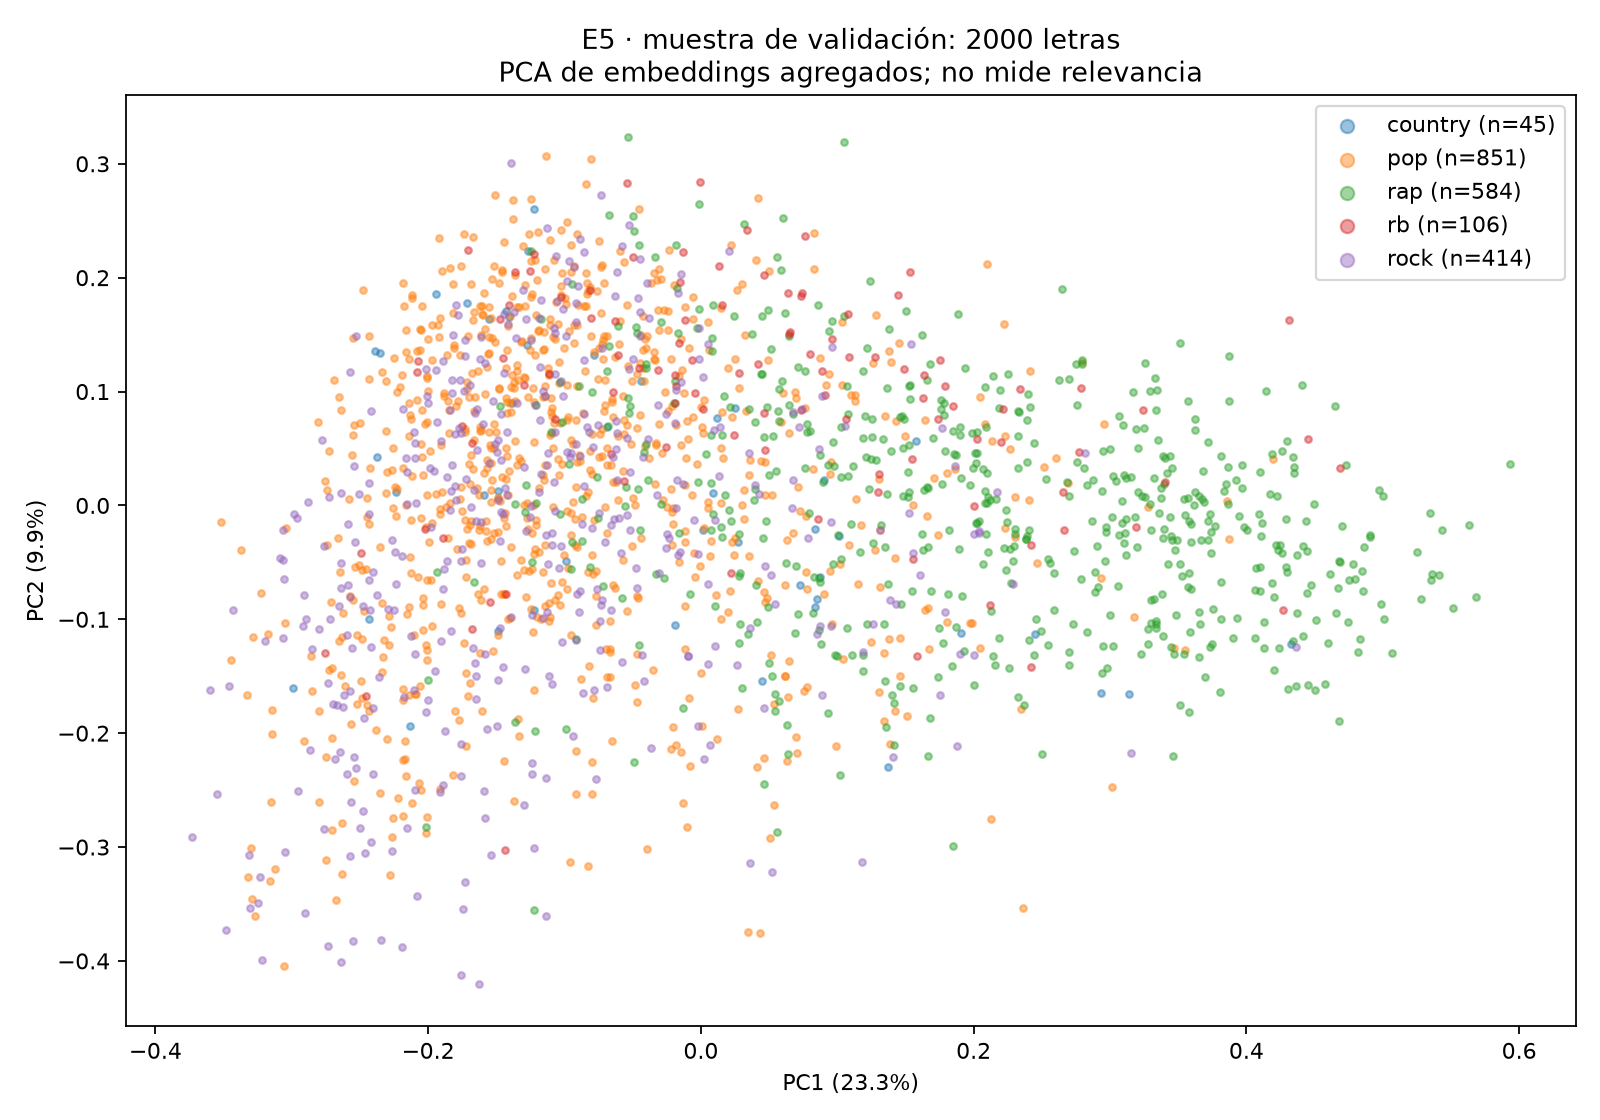

In [3]:
p = analysis['projection']
assert len(set(analysis['sample_ids'])) == analysis['n_projected'] == 2000
print({k:p[k] for k in ('method','svd_solver','n_components','random_state','fit_scope','explained_variance_ratio')})
print('Varianza acumulada:',sum(p['explained_variance_ratio']))
print('Soportes por tag:',dict(Counter(r['tag'] for r in p['points'])))
print('Los 2 000 IDs, coordenadas, media y componentes se conservan en e5_analysis.json.')
display(Image(filename=str(ROOT/'reports/figures/E5/pca_validation.png')))

## 3. Conceptos y contextos compartidos (E5-03/04/05)

In [4]:
for word, result in analysis['concepts'].items():
    display(Markdown('### '+word))
    show([{'vecino': w, 'coseno': c} for w,c in result['static_word_neighbors']])
    show([{'grupo': label, 'letras': g['documents'], 'ocurrencias': g['occurrences'], 'soporte suficiente': g['support_sufficient']} for label,g in result['groups'].items()])
    show(result['contrasts'])
    for label,g in result['groups'].items():
        if label.startswith('tag:'):
            print(label, g['examples'])
print('Umbral:',analysis['minimum_context_support'])
print('El vector estático no cambia; cambian contextos agregados en un mismo espacio.')

### love

| vecino | coseno |
| --- | --- |
| lovе | 0.9406179189682007 |
| unconditionally | 0.6961843967437744 |
| loveeee | 0.6961327791213989 |
| sisterly | 0.6799089908599854 |
| unconditional | 0.6618694067001343 |
| loveeeee | 0.6585808992385864 |
| youand | 0.658164918422699 |
| love'd | 0.643073320388794 |
| plеasure | 0.6401976943016052 |
| cravе | 0.6398720741271973 |

| grupo | letras | ocurrencias | soporte suficiente |
| --- | --- | --- | --- |
| tag:pop | 290 | 1173 | True |
| decade:2000 | 85 | 342 | True |
| decade:2010 | 337 | 1206 | True |
| tag:rap | 200 | 533 | True |
| decade:1990 | 33 | 108 | True |
| decade:1980 | 21 | 61 | True |
| decade:2020 | 150 | 551 | True |
| tag:rock | 91 | 327 | True |
| tag:rb | 57 | 309 | True |
| tag:country | 20 | 86 | True |
| decade:1970 | 18 | 108 | True |
| decade:1950 | 4 | 17 | False |
| decade:1960 | 8 | 19 | False |
| decade:1940 | 1 | 9 | False |
| decade:sin año válido | 1 | 7 | False |

| left | right | context_centroid_cosine |
| --- | --- | --- |
| decade:1970 | decade:1980 | 0.9628238351948573 |
| decade:1970 | decade:1990 | 0.9703569761001021 |
| decade:1970 | decade:2000 | 0.9719519703615948 |
| decade:1970 | decade:2010 | 0.971371384640312 |
| decade:1970 | decade:2020 | 0.9668394151521627 |
| decade:1980 | decade:1990 | 0.9804057591944015 |
| decade:1980 | decade:2000 | 0.9863710541747983 |
| decade:1980 | decade:2010 | 0.9753346174436565 |
| decade:1980 | decade:2020 | 0.9752665951486379 |
| decade:1990 | decade:2000 | 0.9851189519608455 |
| decade:1990 | decade:2010 | 0.9868458190371031 |
| decade:1990 | decade:2020 | 0.9854917443538597 |
| decade:2000 | decade:2010 | 0.9868924056035893 |
| decade:2000 | decade:2020 | 0.9854071713905521 |
| decade:2010 | decade:2020 | 0.9969818344529902 |
| tag:country | tag:pop | 0.9821190259822914 |
| tag:country | tag:rap | 0.9369417964134605 |
| tag:country | tag:rb | 0.9720782218998558 |
| tag:country | tag:rock | 0.9740924189482578 |
| tag:pop | tag:rap | 0.9540094460353791 |
| tag:pop | tag:rb | 0.9874413508043882 |
| tag:pop | tag:rock | 0.9933833552230342 |
| tag:rap | tag:rb | 0.9717164114477603 |
| tag:rap | tag:rock | 0.9532201838153258 |
| tag:rb | tag:rock | 0.979219601098954 |

tag:pop [{'lyrics_id': 'lyr_2cb8bc7d9f7524f3d61d', 'word_index': 57, 'context': ['it', 'twice', 'i', 'got', 'one', 'love', 'for', 'one', 'life', 'forever', 'left']}, {'lyrics_id': 'lyr_5be6a2372d3ecf028343', 'word_index': 6, 'context': ["it's", 'alaine', 'again', "it's", 'another', 'love', 'song', 'yea', 'sing', 'along', 'yea']}]
tag:rap [{'lyrics_id': 'lyr_6eb1350e292960e4d3fb', 'word_index': 374, 'context': ['niggas', 'better', 'revamp', 'price', 'i', 'love', 'to', 'fly', "it's", 'just', 'you']}, {'lyrics_id': 'lyr_e5529959223e4f26b4e2', 'word_index': 26, 'context': ['me', 'cause', 'they', 'say', 'i', 'love', 'the', 'church', 'i', "don't", 'care']}]
tag:rock [{'lyrics_id': 'lyr_35ef40d10eea99e47c7d', 'word_index': 7, 'context': ['let', 'me', 'live', 'inside', 'your', 'love', 'because', 'breathing', 'tends', 'to', 'get']}, {'lyrics_id': 'lyr_edaeb06b5a45a1b3a03a', 'word_index': 121, 'context': ['we', 'mean', 'it', 'man', 'we', 'love', 'our', 'queen', 'god', 'saves', 'god']}]
tag:rb [{

### home

... (14 outputs left out)

### freedom

| vecino | coseno |
| --- | --- |
| liberty | 0.7818216681480408 |
| liberation | 0.7437892556190491 |
| freedoms | 0.7208844423294067 |
| freedom's | 0.7068172693252563 |
| equality | 0.6826518774032593 |
| salvation | 0.6682704091072083 |
| oppression | 0.6495593190193176 |
| appeasement | 0.645383894443512 |
| prosperity | 0.6448619961738586 |
| justice | 0.6411528587341309 |

| grupo | letras | ocurrencias | soporte suficiente |
| --- | --- | --- | --- |
| tag:pop | 6 | 12 | False |
| decade:2000 | 3 | 3 | False |
| decade:1990 | 3 | 8 | False |
| tag:rap | 6 | 9 | False |
| decade:2010 | 11 | 31 | True |
| tag:rb | 3 | 3 | False |
| tag:rock | 7 | 24 | False |
| decade:2020 | 4 | 5 | False |
| decade:1970 | 1 | 1 | False |

Sin resultados con soporte suficiente.
tag:pop [{'lyrics_id': 'lyr_6ce39398c116f5e04ad2', 'word_index': 34, 'context': ['how', 'could', 'i', 'keep', 'this', 'freedom', 'i', 'have', 'from', 'you', 'salvation']}, {'lyrics_id': 'lyr_38092eca20a913f34593', 'word_index': 171, 'context': ['the', 'planet', 'kill', 'each', 'other', 'freedom', 'what', 'a', 'price', 'we', 'pay']}]
tag:rap [{'lyrics_id': 'lyr_44246170badcc68e33df', 'word_index': 167, 'context': ['gonna', 'strip', 'you', 'of', 'your', 'freedom', 'you', 'are', 'out', 'your', 'lane']}, {'lyrics_id': 'lyr_9d7366212cc7e0248ef4', 'word_index': 16, 'context': ['the', 'idea', 'that', 'you', 'have', 'freedom', 'of', 'choice', 'you', "don't", 'you']}]
tag:rb [{'lyrics_id': 'lyr_2df819b0cb74de87ea24', 'word_index': 135, 'context': ['a', 'melody', 'of', 'reason', 'and', 'freedom', 'with', 'words', 'that', 'will', 'speak']}, {'lyrics_id': 'lyr_2baab834d140583fa82c', 'word_index': 268, 'context': ['speakin', 'my', 'mind', "it's", 'my', 'freedo

## 4. Recuperación exacta y contextos para revisión asistida (E5-01)

In [5]:
assert semantic['available_candidates'] == 2208832
assert [q['query']['lyrics_id'] for q in semantic['queries']] == [q['query']['lyrics_id'] for q in lexical['queries']]
for q, base in zip(semantic['queries'], lexical['queries']):
    display(Markdown('### '+q['query']['title']+' · '+q['query']['lyrics_id']))
    show([{'modelo':'SGNS', 'rango':i+1, 'titulo':r['title'], 'artista':r['artist'], 'ID':r['lyrics_id'], 'coseno':r['cosine']} for i,r in enumerate(q['neighbors'])])
    show([{'modelo':'TF-IDF', 'rango':i+1, 'titulo':r['title'], 'ID':r['lyrics_id'], 'coseno':r['cosine']} for i,r in enumerate(base['neighbors'])])
    print('Vecinos comunes:',q['shared_neighbor_ids_with_tfidf'])
for row in audit['retrieval_excerpt_review_material']:
    print(row['lyrics_id'], row['title'], row['excerpt_scope'])
    print(' '.join(row['words']))
print('Extractos de revisión dirigida, no muestra representativa ni juicios gold.')

### Evil dudes demo · lyr_edc300ca1b86e86572b2

| modelo | rango | titulo | artista | ID | coseno |
| --- | --- | --- | --- | --- | --- |
| SGNS | 1 | Jealous Girl | Tages | lyr_4b5afd0dbcaad55c3787 | 0.941381573677063 |
| SGNS | 2 | Girl | Superbus | lyr_583c17af710fd1c3be85 | 0.9400311708450317 |
| SGNS | 3 | Jealous Girl | Johnny Kidd & The Pirates | lyr_085ae63c12623e599f45 | 0.938199520111084 |
| SGNS | 4 | Smile | Barfeye | lyr_3b5c8d21c04fd41e82f2 | 0.9371011257171631 |
| SGNS | 5 | Not You Again | Imogen Heap | lyr_ae60914b8bcbc7f9605d | 0.9365276098251343 |
| SGNS | 6 | You Make Me Happy | Chowdar | lyr_6483d479c72c483a0849 | 0.9358077049255371 |
| SGNS | 7 | Don’t Say You Love Me Single Mix | Erasure | lyr_0a2c41668d792dc7c5b6 | 0.9357063174247742 |
| SGNS | 8 | See You Smile | Peter Harper | lyr_790b741d34a35220e09a | 0.9352005124092102 |
| SGNS | 9 | Melody | Sofie & MISS WORLD | lyr_d2817daf727374b8be65 | 0.9351003170013428 |
| SGNS | 10 | YENA - SMILEY ft. BIBI English Translation | Genius English Translations | lyr_d6e3a6ea117c9210d1db | 0.9349077939987183 |

| modelo | rango | titulo | ID | coseno |
| --- | --- | --- | --- | --- |
| TF-IDF | 1 | Cap Ferrat | lyr_6061843f7703bbe30ef2 | 0.315984308719635 |
| TF-IDF | 2 | Will You Cry When You Hear This Song | lyr_da98da35a44e832720a1 | 0.31543171405792236 |
| TF-IDF | 3 | Always Wrong | lyr_c29ed3bd4d9f010a7732 | 0.31197425723075867 |
| TF-IDF | 4 | Sad Eyes | lyr_cfff342e6cc71fda9abb | 0.3117062747478485 |
| TF-IDF | 5 | Girl | lyr_583c17af710fd1c3be85 | 0.30858251452445984 |
| TF-IDF | 6 | Never Let You Know | lyr_9b2530f565739933f603 | 0.307964026927948 |
| TF-IDF | 7 | Something To Cry To | lyr_7877c89cb37ca3539bc7 | 0.29946696758270264 |
| TF-IDF | 8 | I Just Want You To Know | lyr_8bc0c4c61173d02104b9 | 0.2913269102573395 |
| TF-IDF | 9 | August | lyr_d34a66ab243176fc997e | 0.2905888557434082 |
| TF-IDF | 10 | Swing Pool | lyr_7159c1f0b4cff91ecee2 | 0.28867781162261963 |

Vecinos comunes: ['lyr_583c17af710fd1c3be85']


### Eat For Two MTV Unplugged · lyr_15c965067a70c0fe209c

| modelo | rango | titulo | artista | ID | coseno |
| --- | --- | --- | --- | --- | --- |
| SGNS | 1 | Wandering Daughter | Kimya Dawson | lyr_7633385cdeca9f3aa0c8 | 0.9629358649253845 |
| SGNS | 2 | Go Long | Joanna Newsom | lyr_ff9fa20ed20f01cb9d8d | 0.9627977609634399 |
| SGNS | 3 | Blame Yourself | Logan182 | lyr_31b0692041f8d15cbaa9 | 0.9627445936203003 |
| SGNS | 4 | The Ballad of Noah | k-os | lyr_33d177c0141c1049d916 | 0.9624509215354919 |
| SGNS | 5 | Bad Idea | The Devil Makes Three | lyr_a8bb1b660917e44cc26a | 0.9624389410018921 |
| SGNS | 6 | Supersede | Jackie Greene | lyr_551a9d7cd9e51cb7ae99 | 0.9623875021934509 |
| SGNS | 7 | For What Its Worth | Ryan Bingham | lyr_2e13a4dfce49822b1c4e | 0.9621710777282715 |
| SGNS | 8 | The Moon Looked Down And Laughed | Virgin Prunes | lyr_cf24f290289dd47a848a | 0.9620581269264221 |
| SGNS | 9 | Queen Of Fortune | Monks Of Doom | lyr_4b69162ff38e46b9e74d | 0.9619963765144348 |
| SGNS | 10 | Az in manzareh | Koorosh | lyr_a8d7c3b2519ec6ae71f8 | 0.961937665939331 |

... (10 outputs left out)

### Ive Gotten Used To The Cryin · lyr_99e2f1f42b99ea8a6117

| modelo | rango | titulo | artista | ID | coseno |
| --- | --- | --- | --- | --- | --- |
| SGNS | 1 | I’ve Cried Before | Dion and The Belmonts | lyr_58ea5de130130868e4c4 | 0.947725772857666 |
| SGNS | 2 | Mississippi Delta City Blues | Chicago | lyr_247d984a31b30d125e9f | 0.9467711448669434 |
| SGNS | 3 | Ive Cried Before | Dion | lyr_b3ea1b641100e546ea67 | 0.9464793801307678 |
| SGNS | 4 | On My Mind | Flatt & Scruggs | lyr_4bad42e9ffec164dd778 | 0.9448109269142151 |
| SGNS | 5 | Waitin For the Day | Zachary Lucky | lyr_15b3ed55fcf5b3130960 | 0.9445262551307678 |
| SGNS | 6 | Who Youre With | Language of Flowers | lyr_3116bb1070561ba77287 | 0.9444910883903503 |
| SGNS | 7 | Mississippi Delta City Blues Live In Japan | Chicago | lyr_d094bbed029a26165771 | 0.9443111419677734 |
| SGNS | 8 | BRKN | Madison Ryann Ward | lyr_165c3502e56e00312e5a | 0.9433945417404175 |
| SGNS | 9 | On My Mind | Skeeter Davis | lyr_f4444ad3951049fb7d3c | 0.9433115124702454 |
| SGNS | 10 | Id Do It All Again | Eloise Laws | lyr_bd5e8a92b27bed64241b | 0.9432557821273804 |

| modelo | rango | titulo | ID | coseno |
| --- | --- | --- | --- | --- |
| TF-IDF | 1 | You Got Me Cryin | lyr_439873e0c8532047372a | 0.3884734809398651 |
| TF-IDF | 2 | You Got Me Crying | lyr_30d79c6ac8bc07a0a04e | 0.320626437664032 |
| TF-IDF | 3 | You Got Me Crying | lyr_88c7ecd5a8eac756a00d | 0.30777207016944885 |
| TF-IDF | 4 | Im Getting Used To You | lyr_38c7ae9e88422f60e21e | 0.29971179366111755 |
| TF-IDF | 5 | Were Together Again | lyr_718b1145d514818088e5 | 0.2906258702278137 |
| TF-IDF | 6 | Last Minutes of the Memory | lyr_2009301f0ab882d58909 | 0.28869158029556274 |
| TF-IDF | 7 | Crying | lyr_2d3c90587f1064d0c174 | 0.28371813893318176 |
| TF-IDF | 8 | Sukarita | lyr_d89ed61ed2acb9667f5b | 0.28338006138801575 |
| TF-IDF | 9 | I Got You | lyr_8533b4b47dd636bd9bf2 | 0.27649059891700745 |
| TF-IDF | 10 | The Game skit | lyr_a1d9c345d24307b104d7 | 0.2742723226547241 |

Vecinos comunes: []
lyr_ff9fa20ed20f01cb9d8d Go Long first <=180 surface words, not whole lyric
last night again you were in my dreams several expendable limbs were at stake you were a prince spinning rims all sentiments indian given and half baked i was brought in on a palanquin made of the many bodies of beautiful women brought to this place to be examined swaying on an elephant a princess of india we both want the very same thing we are praying i am the one to save you but you don't even own your own violence run away from home your beard is still blue with the loneliness of you mighty men with your jaws and fists and guitars and pens and your sugarlip but i've never been to the firepits with you mighty men who made you this way who made you this way who is going to bear your beautiful children do you think you can just stop when you're ready for a change who will take care of you when you're old and dying you burn in the mekong to prove your worth go long go long right over the edg

## 5. LDA y resultado temático limitado

In [6]:
lda = read(MODELS/'lda/lda_selection.json')
show([{k:v for k,v in c.items() if k not in ('path','top_words')} for c in lda['candidates']])
show([{'topico':i, 'terminos top10':', '.join(words), 'masa media train':audit['topic_mean_by_split']['train'][i]} for i,words in enumerate(lda['selected']['top_words'])])
print('Estabilidad:',lda['seed_stability']['method'])
print('Jaccard medio:',lda['seed_stability']['mean_jaccard'])
show(lda['seed_stability']['matches'])
print('Masa train tópicos 0/4/14:',sum(audit['topic_mean_by_split']['train'][i] for i in (0,4,14)))
print('No se incorporan tópicos al ranking; faltan ablación y juicios de validación.')

| k | seed | validation_gensim_bound_per_word | validation_u_mass | topic_diversity_top10 |
| --- | --- | --- | --- | --- |
| 20 | 42 | -9.310045956768397 | -7.550187836390856 | 0.775 |
| 40 | 42 | -10.691583764061217 | -6.541798182661973 | 0.4775 |
| 20 | 43 | -9.257947873238535 | -7.3507774604949265 | 0.645 |

| topico | terminos top10 | masa media train |
| --- | --- | --- |
| 0 | of, my, is, your, we, for, all, this, are, that | 0.4541820280283932 |
| 1 | u, hello, ahh, sunset, ta, lone, heavenly, gunna, rum, pum | 0.0011822532774667 |
| 2 | go, on, down, come, im, la, let's, dance, high, gonna | 0.01763992733377662 |
| 3 | di, seh, suh, wid, dey, neva, shi, gwaan, ova, ina | 0.00044036076899697015 |
| 4 | my, i'm, like, it, on, up, got, that, me, they | 0.25548431129718946 |
| 5 | 𝙮𝙤𝙪, 𝙩𝙝𝙚, 𝙄, 𝘺𝘰𝘶𝘳, 𝘺𝘰𝘶, 𝘺𝘦𝘢𝘩, 𝘸𝘪𝘵𝘩, 𝘸𝘩𝘢𝘵, 𝘸𝘦, 𝘸𝘢𝘴 | 0.00034860475376433635 |
| 6 | ey, wana, imma, dey, dont, ion, janny, kpe, coz, ima | 0.0003919538427188458 |
| 7 | ee, dammit, bup, olowo, employers, employer, thema, damm, william, brilliant | 0.00037622940585797283 |
| 8 | lo, darlin, realise, whispering, hum, centuries, denying, sha, today's, speechless | 0.0005651632227209877 |
| 9 | du, ie, dudu, dudududududu, consolation, mir, bist, schön, bei, rеcognize | 0.0003776093641583218 |
| 10 | 𝙮𝙤𝙪, 𝙩𝙝𝙚, 𝙄, 𝘺𝘰𝘶𝘳, 𝘺𝘰𝘶, 𝘺𝘦𝘢𝘩, 𝘸𝘪𝘵𝘩, 𝘸𝘩𝘢𝘵, 𝘸𝘦, 𝘸𝘢𝘴 | 0.00034860475376433635 |
| 11 | she, her, girl, ah, she's, love, said, body, night, ha | 0.010971735163590353 |
| 12 | eh, meth, ga, dey, oooo, ahhhhhh, oya, oluwa, nani, sey | 0.0004709265721715065 |
| 13 | da, ba, dat, dey, data, ima, dont, dam, digga, imma | 0.0009322721986995025 |
| 14 | me, it, i'm, don't, know, my, just, that, love, be | 0.23958036059539395 |
| 15 | 𝙮𝙤𝙪, 𝙩𝙝𝙚, 𝙄, 𝘺𝘰𝘶𝘳, 𝘺𝘰𝘶, 𝘺𝘦𝘢𝘩, 𝘸𝘪𝘵𝘩, 𝘸𝘩𝘢𝘵, 𝘸𝘦, 𝘸𝘢𝘴 | 0.00034860475376433635 |
| 16 | 𝙮𝙤𝙪, 𝙩𝙝𝙚, 𝙄, 𝘺𝘰𝘶𝘳, 𝘺𝘰𝘶, 𝘺𝘦𝘢𝘩, 𝘸𝘪𝘵𝘩, 𝘸𝘩𝘢𝘵, 𝘸𝘦, 𝘸𝘢𝘴 | 0.00034860475376433635 |
| 17 | yeah, oh, ooh, hey, na, uh, woah, nah, ayy, mmm | 0.013240279273738742 |
| 18 | prays, crusader, parted, mistrust, sagged, servants, unbroken, crushing, monarchy, magistrate | 0.0003536343998547784 |
| 19 | o, n, lonely, s, e, ok, d, f, l, linger | 0.0024164584038276833 |

Estabilidad: Hungarian maximum top10-term Jaccard, seed42 vs seed43 at selected K
Jaccard medio: 0.3642278043593833


| seed42_topic | seed43_topic | jaccard |
| --- | --- | --- |
| 0 | 9 | 0.6666666666666666 |
| 1 | 0 | 0.05263157894736842 |
| 2 | 1 | 0.1111111111111111 |
| 3 | 11 | 0.0 |
| 4 | 2 | 1.0 |
| 5 | 7 | 1.0 |
| 6 | 10 | 0.1111111111111111 |
| 7 | 3 | 0.0 |
| 8 | 4 | 0.0 |
| 9 | 15 | 0.0 |
| 10 | 8 | 1.0 |
| 11 | 12 | 0.1111111111111111 |
| 12 | 18 | 0.05263157894736842 |
| 13 | 6 | 0.1111111111111111 |
| 14 | 14 | 0.8181818181818182 |
| 15 | 13 | 1.0 |
| 16 | 16 | 1.0 |
| 17 | 19 | 0.0 |
| 18 | 17 | 0.0 |
| 19 | 5 | 0.25 |

Masa train tópicos 0/4/14: 0.9492466999209765
No se incorporan tópicos al ranking; faltan ablación y juicios de validación.


## 6. Interpretación asistida, límites y matriz de requisitos

# E5 — semántica: resultados y revisión técnica

2026-11-16. **Cierre técnico/documental completado; revisión asistida realizada;
revisión personal del autor pendiente (H12).** Protocolo: [E5_METODO.md](../../docs/E5_METODO.md).
Evidencia: [notebook ejecutado](../notebooks/evidencias/E5_semantica.ipynb).
Los juicios asistidos no son gold ni una medición de accuracy.

## Universo, cobertura y procedencia

La corrida `e5-surface-v2` terminó a las **20:07:02 America/Mexico_City**. Se
reutilizó el corpus completo de diez shards, sin repetir ingesta, idioma o spaCy.
La auditoría `scripts/verify_e5_results.py` verificó hashes de las representaciones
y todos los checkpoints publicados; su salida real es
`reports/nlp/lyrics_full_v1/e5_verification.json`.

| Split | Letras transformadas | Tokens superficiales |
|---|---:|---:|
| train | 2 208 832 | 631 669 490 |
| validation | 315 289 | 90 048 892 |
| test | 631 651 | 180 657 971 |
| Total | 3 155 772 | 902 376 353 |

Se verificaron **3 155 772 IDs únicos**, todos con embedding y tópicos disponibles.
Disponibilidad por letra no equivale a cobertura léxica total: el vocabulario de
100 000 términos cubre **738 990 323 tokens**, 81,901 % de train, 81,875 % de
validation y 81,878 % de test. OOV se omite. Son tokens regex, distintos de spaCy.

Vectores: 128 dimensiones, finitos, error máximo de norma L2 **1,79×10⁻⁷**.
Tópicos: 20 componentes finitas, no negativas, error máximo de suma a uno
**1,02×10⁻⁶**. Inspeccionar test aquí comprueba integridad de transformación,
sin juicios de relevancia, ajuste ni selección. Se conserva `lyrics_id`; el enlace
a grabaciones/track_id pertenece al catálogo verificado, todavía pendiente de audio.

Espacio común: `ec76a8c38600ad837729631f95a54d58ac2c983ae46c7259aded6897235d9479`.
Su firma identifica modelos, vocabulario y política de exportación.

## Embeddings propios y selección

Se entrenaron dos **Word2Vec/SGNS propios**, ventanas máximas 5 y 10, 128
dimensiones, cinco negativos, semilla 42 y tres épocas de todo train. Cada época
recorre 631 669 490 palabras brutas. Se verificaron los checkpoints 0–3 de ambos
modelos. Cuatro workers aceleran la ejecución, sin reproducibilidad bit a bit.

| Ventana | Objetivo SGNS medio en validation | Pares positivos |
|---|---:|---:|
| **5, seleccionada** | **−2,392892** | 100 000 |
| 10 | −2,401978 | 100 000 |

Fuente: `artifacts/models/lyrics_full_v1/e5-surface-v2/sgns_selection.json`.
Gana el mayor objetivo con los mismos pares/negativos. El tope de pares limita
el diagnóstico; no mide calidad de recomendación. El pooling suma palabras
distintas con TF-IDF sublineal y normaliza L2, sin duplicar el efecto de frecuencia.
No se filtra por POS ni se depende de lemas dudosos.

## Recuperación y casos de acierto parcial/fallo

TF-IDF y SGNS recuperaron diez vecinos para las mismas cinco consultas de
validation contra **2 208 832 candidatos de train**, sin construir N×N.
Fuentes: `reports/nlp/lyrics_full_v1/e5_{tfidf,embedding}_retrieval.json`.
La auditoría guarda extractos de hasta 180 palabras de consultas y dos primeros
vecinos SGNS. Las lecturas siguientes se basan en esos extractos y son asistidas,
no juicios gold. No se evalúa test.

| Consulta (validation) | Primer vecino SGNS (train) / coseno | Lectura contextual asistida | Vecinos comunes top-10 TF-IDF/SGNS |
|---|---|---|---:|
| Evil dudes demo · `lyr_edc300ca1b86e86572b2` | Jealous Girl, Tages · `lyr_4b5afd0dbcaad55c3787` / 0,941382 | Tristeza, llanto y sonrisa mediante apelación a otra persona: acierto parcial de relación afectiva. Celos/amor del vecino no quedan establecidos en la consulta. | 1 |
| Eat For Two MTV Unplugged · `lyr_15c965067a70c0fe209c` | Wandering Daughter, Kimya Dawson · `lyr_7633385cdeca9f3aa0c8` / 0,962936 | Embarazo y vivir por dos en la consulta; identidad filial, dolor e imágenes de cuento en el vecino. Registro metafórico compartido, pero fallo si se busca el tema específico del embarazo. Go Long, segundo vecino, tampoco lo confirma en su extracto. | 0 |
| Plug Music · `lyr_6eb1350e292960e4d3fb` | Hibachi, Smoke DZA · `lyr_e301e5c9d0097727221a` / 0,983038 | Dinero, pares y supervivencia/calle sostienen relación parcial. La promesa de cuidado del inicio de la consulta no queda igualmente reflejada; la media pierde estructura y voces. | 0 |
| The Way You Were · `lyr_c7ae2a9804278ee4fca3` | Walk Away, Peltsman · `lyr_f373b1191ddc8a004546` / 0,968649 | Discusión, distancia y separación ofrecen afinidad temática aunque cambia rb→rap; no prueba semejanza sonora. | 0 |
| Ive Gotten Used To The Cryin · `lyr_99e2f1f42b99ea8a6117` | I’ve Cried Before, Dion and The Belmonts · `lyr_58ea5de130130868e4c4` / 0,947726 | Llanto, dolor amoroso y ruptura ofrecen relación plausible. Mississippi Delta City Blues, segundo vecino, también trata ocultación del dolor. No se verifican covers. | 0 |

Los rankings son diferentes; el solapamiento no decide cuál es mejor. Cosenos
SGNS altos no son probabilidades ni se comparan directamente con TF-IDF.
La media pierde orden, negación y composición. Las palabras funcionales pueden
estrechar ángulos, pero aquí no se demuestra la causa de los scores elevados.
Faltan juicios independientes para medir calidad del recomendador.

La interfaz `pipelines/nlp/recommend_e5.py` completó una consulta real de cinco
vecinos contra todo train. [Uso y límites](../../docs/E5_RECOMMENDATIONS.md). No incorpora
audio, filtros por artista/covers ni UI interactiva.

## PCA: parámetros y revisión visual

![PCA de validación](../../reports/figures/E5/pca_validation.png)

Dos componentes, `svd_solver=full`, `random_state=42`; ajuste sólo a las **2 000
letras de validation con menores SHA-256 de lyrics_id**. Todas se proyectaron.
IDs, coordenadas, media/componentes: `e5_analysis.json`. PC1 explica **23,323 %**
y PC2 **9,852 %**, total **33,176 %**. El resto de variación no se representa.
Muestra: country 45, pop 851, rap 584, rb 106, rock 414.

Figura inspeccionada visualmente: título, porcentajes y leyenda legibles, sin
recortes. Rap se concentra más hacia PC1 positivo, con considerable solapamiento;
pop/rock se extienden hacia negativo y se mezclan ampliamente. Esto describe
esta muestra/proyección, sin demostrar separación de géneros, significancia,
clusters musicales o calidad de recomendación.

## Conceptos y variación de contextos

Los cinco conceptos usan **el mismo SGNS estático**, contextos ±5 palabras y
promedios con igual peso por letra. Las ocurrencias conservan repeticiones.
Umbral descriptivo: ≥10 letras y ≥20 ocurrencias. Un vecino puede ser colocación,
oposición o relación temática, no necesariamente sinónimo.

| Concepto | Relación observada | Soporte y variación |
|---|---|---|
| love | `unconditionally` 0,696 y `unconditional` 0,662 asocian modo de amar. `lovе` 0,941 es variante gráfica, no descubrimiento conceptual. | Todos los tags con soporte: pop 290 letras/1 173 ocurrencias; rap 200/533; rock 91/327; rb 57/309; country 20/86. Décadas desde 1970 comparables; 1940/1950/1960 insuficientes. Coseno 1970–1980: 0,963, sin prueba de cambio. |
| home | `homesick` 0,625, `back` 0,590 y `homeplace` 0,630 relacionan añoranza, retorno y lugar. Los nombres propios entre vecinos no son sinónimos. | Pop 98/209, rock 41/86 y rap 69/117 con soporte; country 10/16 y rb 9/11 no. `lyr_668235a57971fbdccdd6`, posición 18, combina vivienda y soledad. Coseno 1990–2000: 0,953. |
| money | `cash` 0,789, `guap` 0,721 y `dough` 0,707 relacionan dinero; polisemia requiere contexto. `monеy` 0,906 es variante gráfica. | Rap 155/501, pop 28/79, rock 17/26; rb 6/8 y country 1/1 insuficientes. Búsqueda de dinero en `lyr_e9b51d5a7255fd900a8a`, posición 68; estatus familiar en `lyr_fc94c9c5d4855c7ff8cf`, posición 5. Coseno 2010–2020: 0,992, contraste casi nulo en este espacio. |
| war | `battle` 0,741, `warfare` 0,680 y `bloodshed` 0,676 relacionan conflicto; `waging` 0,772 es colocación. | Rap 25/68, pop 16/20 y rock 13/20 admiten contraste por tag (0,910–0,943). Sólo 2010 supera umbral temporal: no hay contraste entre décadas. Contexto de tácticas/matar: `lyr_2007784ddfd8a9422a73`, posición 19. |
| freedom | `liberty` 0,782 y `liberation` 0,744 próximos; `oppression` 0,650 es oposición/tema, no sinónimo. | Ningún tag supera umbral; rock 7/24 sigue insuficiente. Sólo 2010 tiene soporte (11/31): **no hay contrastes**. Se conservan ejemplos de salvación y libertad de elección. |

Fuente completa, incluidos grupos insuficientes y ejemplos con ID/posición:
`e5_analysis.json`. Años/tags son metadatos de fuente, no fechas de composición
o géneros validados. Mezcla de artistas, longitud, repetición y escasez histórica
limitan comparaciones. El vector de cada palabra no cambia; cambian sus contextos
promediados. No se comparan modelos temporales independientes ni se afirma
evolución causal del significado.

## Tópicos: resultado negativo que se conserva

LDA online: conteos de train, mismo vocabulario, priors simétricos, 30 iteraciones,
una pasada, conservando stopwords. Selección entre seed42 por mayor cota variacional
por palabra en la misma muestra de validación.

| K / semilla | Cota por palabra | UMass | Diversidad top-10 |
|---|---:|---:|---:|
| **20 / 42, seleccionado** | **−9,310046** | −7,550188 | 0,7750 |
| 40 / 42 | −10,691584 | −6,541798 | 0,4775 |
| 20 / 43, estabilidad | −9,257948 | −7,350777 | 0,6450 |

K=40 tiene UMass menos negativo, pero pierde el criterio predefinido. Seed43
diagnostica estabilidad y no sustituye retrospectivamente al modelo elegido.
La cota no es perplexity normalizada ni se compara con KenLM de E2.
Se verificaron los diez checkpoints de cada una de las tres corridas.

Emparejamiento húngaro top-10 seed42/43: Jaccard medio **0,364228**, mínimo **0**;
seis de veinte emparejamientos son cero. Varios 1,0 corresponden a listas
tipográficas repetidas: no prueban estabilidad temática. En seed42 los tópicos
5, 10, 15 y 16 comparten la misma lista estilizada: redundancia/degeneración.

Tópicos 0/4/14 dominados por funcionales/pronombres concentran **94,925 %** de la
masa temática media por letra en train (45,418 %, 25,548 %, 23,958 %).
El 17 agrupa vocalizaciones; el 11 incluye pronombres femeninos/vocabulario afectivo;
el 18 mezcla conflicto y autoridad sin etiqueta única defendible. No se asignan
emociones. Aparecen formas dialectales, multilingües y Unicode; no se excluyen
letras ni se infiere idioma por esos términos aislados.

La pasada única no demuestra convergencia; Gensim lo advirtió. Las distribuciones
son numéricamente válidas y temáticamente limitadas. **No se incorporan al ranking**:
falta ablación con juicios de validación. Una variante de stopwords/Unicode tendría
versión propia; no se reescribe esta corrida ni se modifica E3 silenciosamente.

## Matriz de cierre

| Requisito | Evidencia ejecutada | Estado técnico |
|---|---|---|
| E5-01 | SGNS propio completo, selección, pooling/normalización; dos rankings y revisión contextual de aciertos parciales/fallos | Completado; sin evaluación de relevancia |
| E5-02 | PCA real, muestra/IDs, parámetros/varianza y figura revisada visualmente | Completado |
| E5-03 | Cinco conceptos, vecinos y relaciones con ocurrencias verificables | Completado |
| E5-04 | Contextos por tag/década, soportes, sesgos y contrastes nulos/insuficientes conservados | Completado como descripción |
| E5-05 | Un espacio común, versión exportada y distinción vector estático/contexto | Completado |

Suite vigente: **48 passed** con fixtures sintéticos; no son métricas del corpus.
La auditoría real se registra por separado. La interrupción se reanudó desde
checkpoints sin cambiar código/configuración; consultar marcadores finales,
no los porcentajes históricos del handoff.

Pendiente personal: [TODO-human.md](../../TODO-human.md), **H12**, confirmar/corregir
interpretaciones y figura. E3/E4 mantienen sus pendientes. Cierre técnico no
significa aprobación del autor, evaluación del recomendador ni integración de audio.